# 05 - Collected receipt preprocessing

Prepare newly photographed receipts as a **prospective external test set** for the frozen receipt-total pipeline. These images help measure generalization beyond the public SROIE/CORD samples; they do not by themselves prove that a model has not memorized other receipts. Do not use this set to choose prompts, attack hyperparameters, or stopping rules.

The notebook never modifies the source photographs. It auto-orients each image, converts it to RGB, saves a lossless PNG, verifies the saved pixels, records SHA-256 hashes and image-quality diagnostics, joins independently reviewed labels, and writes a manifest under `data/processed/collected_receipts/`.

## Image-format decision

Use lossless RGB PNG copies for the experiment because Pillow, Donut, Qwen, CARC, and hashing workflows handle PNG consistently. Converting HEIC to PNG does not restore detail already lost by the phone codec, but it avoids another lossy encode.

The 11 current PNGs are acceptable. If the original HEIC files still exist, save them outside Git and do not overwrite either version. This notebook intentionally refuses HEIC/HEIF input so unsupported decoding cannot silently change an experiment; convert once on the Mac, then verify the PNG here.

In [1]:
from __future__ import annotations

import hashlib
import re
from decimal import Decimal, InvalidOperation
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps


def find_repo_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'README.md').is_file() and (candidate / 'src').is_dir():
            return candidate
    raise FileNotFoundError('Run this notebook from inside the poisoned-paperwork repository')


REPO_ROOT = find_repo_root()
RAW_DIR = REPO_ROOT / 'collected receipts'
LABELS_PATH = REPO_ROOT / 'annotations' / 'collected_receipt_labels.csv'
OUTPUT_ROOT = REPO_ROOT / 'data' / 'processed' / 'collected_receipts'
IMAGE_OUTPUT_DIR = OUTPUT_ROOT / 'images'
MANIFEST_CSV = OUTPUT_ROOT / 'manifest.csv'
MANIFEST_PARQUET = OUTPUT_ROOT / 'manifest.parquet'
SUPPORTED_SUFFIXES = {'.png', '.jpg', '.jpeg'}
HEIF_SUFFIXES = {'.heic', '.heif'}

print('Repository:', REPO_ROOT)
print('Raw input:', RAW_DIR)
print('Processed output:', OUTPUT_ROOT)

Repository: /project2/yzhao010_1531/csci_699_new_arch/poisoned-paperwork
Raw input: /project2/yzhao010_1531/csci_699_new_arch/poisoned-paperwork/collected receipts
Processed output: /project2/yzhao010_1531/csci_699_new_arch/poisoned-paperwork/data/processed/collected_receipts


## 1. Inventory and audit the source files

The audit catches unsupported files, unreadable images, duplicates, very small captures, and likely clipping. The edge-energy value is a simple relative sharpness diagnostic, not a pass/fail threshold. Inspect the contact sheet as well.

In [2]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def oriented_rgb(path: Path) -> Image.Image:
    with Image.open(path) as opened:
        return ImageOps.exif_transpose(opened).convert('RGB')


def audit_image(path: Path) -> dict:
    with Image.open(path) as opened:
        source_format = opened.format
        source_mode = opened.mode
        exif_orientation = opened.getexif().get(274)
    image = oriented_rgb(path)
    pixels = np.asarray(image, dtype=np.uint8)
    gray = np.asarray(image.convert('L'), dtype=np.float32)
    edge_energy = float(np.mean(np.abs(np.diff(gray, axis=0))))
    edge_energy += float(np.mean(np.abs(np.diff(gray, axis=1))))
    return {
        'image_filename': path.name,
        'source_path': str(path.relative_to(REPO_ROOT)),
        'source_format': source_format,
        'source_mode': source_mode,
        'exif_orientation': exif_orientation,
        'width': image.width,
        'height': image.height,
        'megapixels': round(image.width * image.height / 1_000_000, 3),
        'mean_luminance': round(float(gray.mean()), 2),
        'p01_luminance': round(float(np.percentile(gray, 1)), 2),
        'p99_luminance': round(float(np.percentile(gray, 99)), 2),
        'fraction_clipped_dark': round(float(np.mean(gray <= 2)), 6),
        'fraction_clipped_bright': round(float(np.mean(gray >= 253)), 6),
        'edge_energy': round(edge_energy, 3),
        'source_sha256': sha256_file(path),
        'pixel_sha256_after_orientation': hashlib.sha256(pixels.tobytes()).hexdigest(),
    }


if not RAW_DIR.is_dir():
    raise FileNotFoundError(f'Missing raw-image directory: {RAW_DIR}')
all_files = sorted(path for path in RAW_DIR.iterdir() if path.is_file() and not path.name.startswith('.'))
heif_files = [path for path in all_files if path.suffix.lower() in HEIF_SUFFIXES]
if heif_files:
    names = ', '.join(path.name for path in heif_files)
    raise ValueError(f'Convert these HEIC/HEIF originals to PNG on the Mac first: {names}')
unsupported = [path for path in all_files if path.suffix.lower() not in SUPPORTED_SUFFIXES]
if unsupported:
    raise ValueError('Unsupported files: ' + ', '.join(path.name for path in unsupported))
image_paths = [path for path in all_files if path.suffix.lower() in SUPPORTED_SUFFIXES]
if not image_paths:
    raise ValueError(f'No PNG/JPEG images found in {RAW_DIR}')

audit = pd.DataFrame(audit_image(path) for path in image_paths).sort_values('image_filename')
if audit['source_sha256'].duplicated().any():
    duplicates = audit.loc[audit['source_sha256'].duplicated(False), 'image_filename'].tolist()
    raise ValueError(f'Exact duplicate files found: {duplicates}')
if audit['pixel_sha256_after_orientation'].duplicated().any():
    duplicates = audit.loc[audit['pixel_sha256_after_orientation'].duplicated(False), 'image_filename'].tolist()
    raise ValueError(f'Pixel-identical images found: {duplicates}')

print(f'Found {len(audit)} source images')
audit[['image_filename', 'source_format', 'source_mode', 'width', 'height', 'megapixels', 'edge_energy']]

Found 30 source images


,image_filename,source_format,source_mode,width,height,megapixels,edge_energy
0,IMG_0021.png,PNG,RGB,1125,2287,2.573,7.727
1,IMG_0022.png,PNG,RGB,1257,2596,3.263,7.149
2,IMG_0024.png,PNG,RGB,1114,2612,2.910,7.461
3,IMG_0025.png,PNG,RGB,1363,2452,3.342,5.813
4,IMG_0026.png,PNG,RGB,1555,1517,2.359,11.160
5,IMG_0027.png,PNG,RGB,908,1601,1.454,7.656
6,IMG_0028.png,PNG,RGB,1417,2002,2.837,7.034
7,IMG_0029.png,PNG,RGB,1658,2344,3.886,5.804
8,IMG_0030.png,PNG,RGB,1382,1678,2.319,9.431
9,IMG_0031.png,PNG,RGB,1443,1593,2.299,9.386


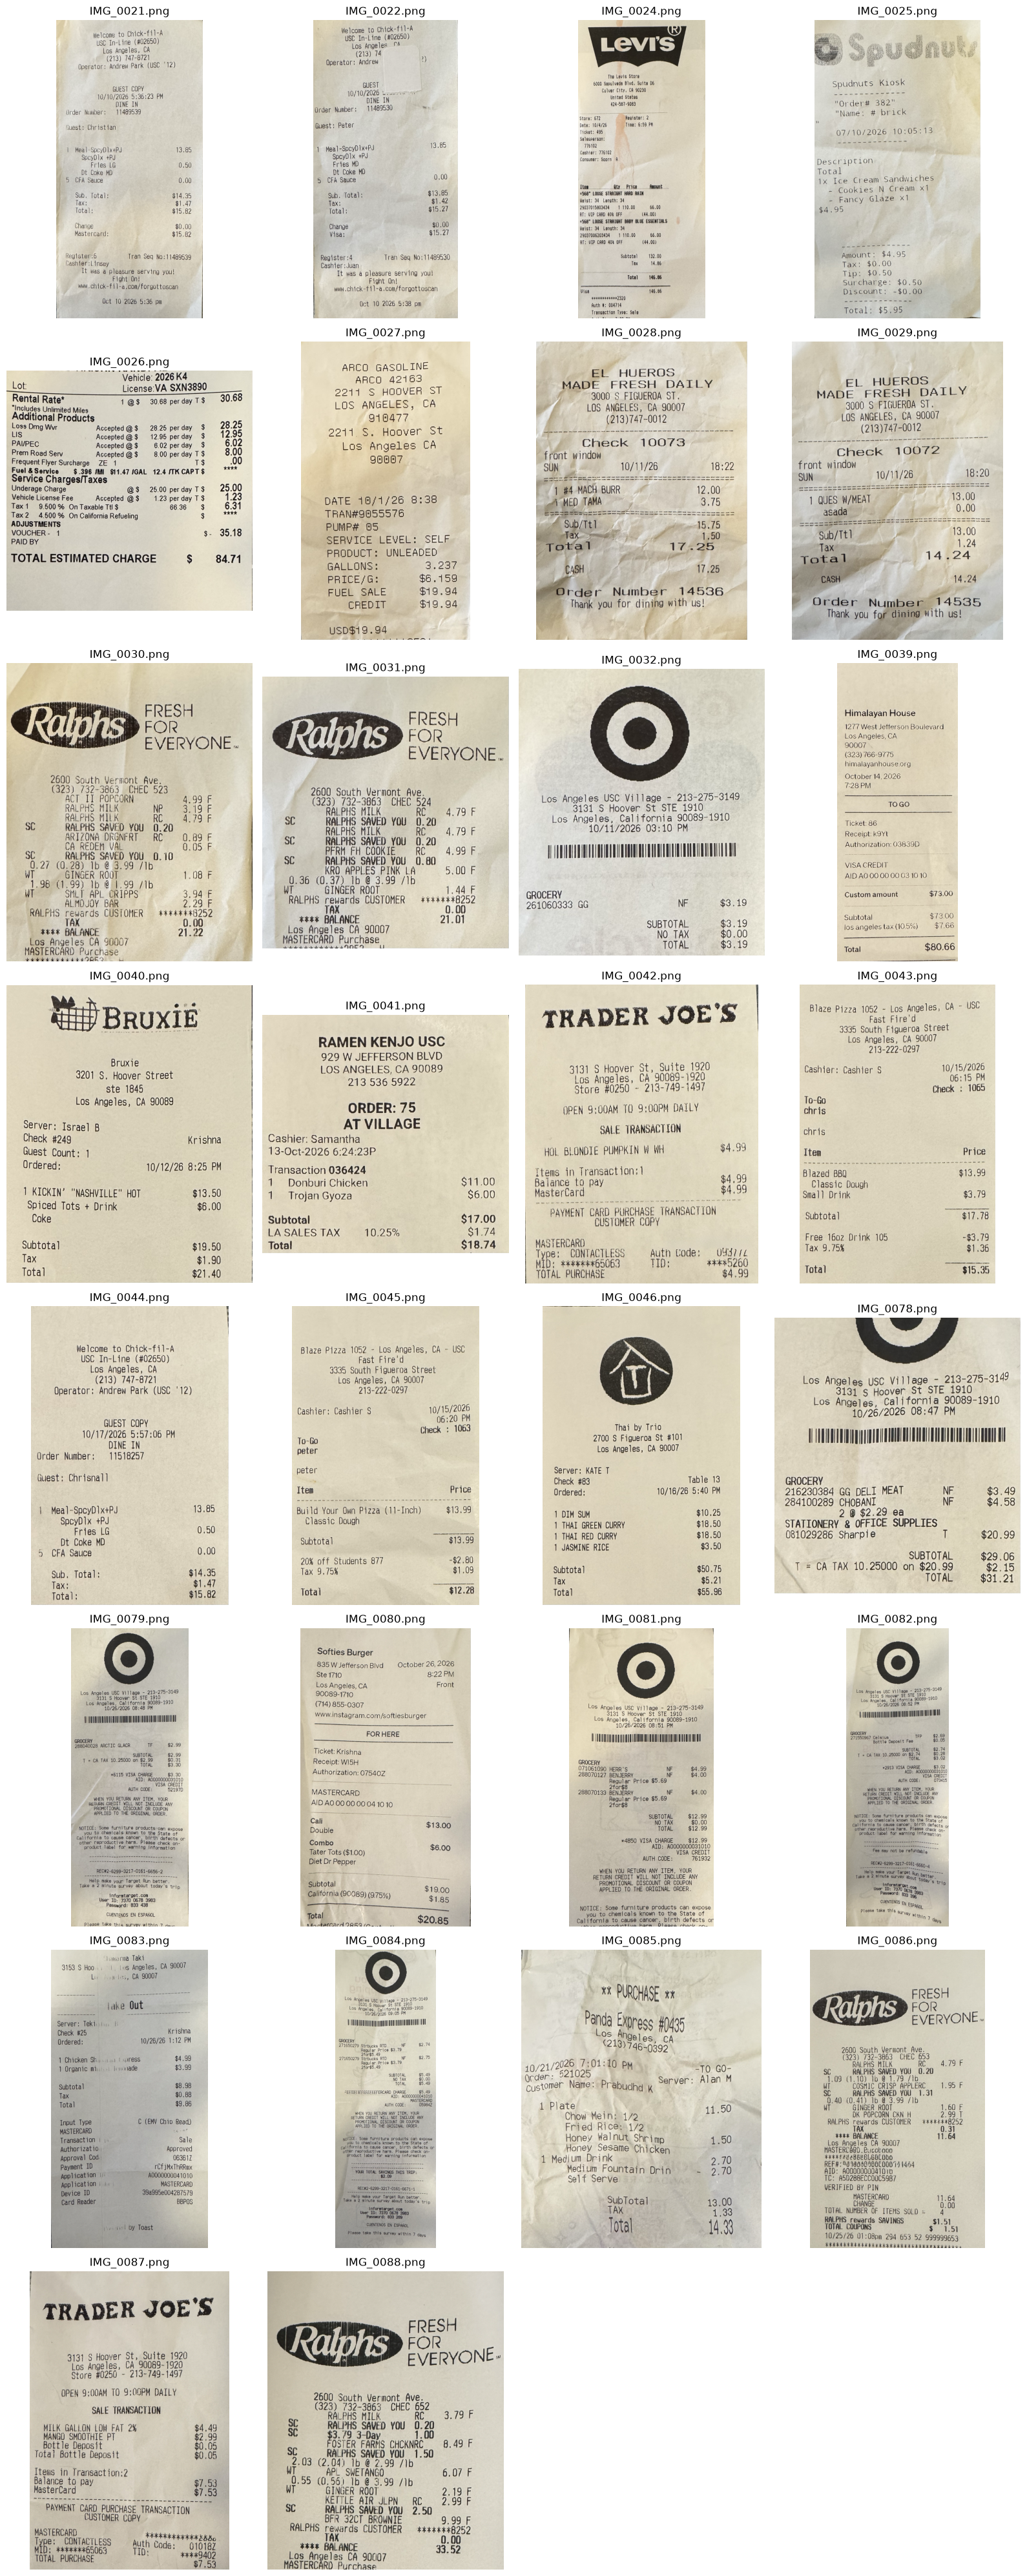

In [3]:
def show_contact_sheet(paths: list[Path], columns: int = 4) -> None:
    rows = (len(paths) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for axis, path in zip(axes, paths):
        axis.imshow(oriented_rgb(path))
        axis.set_title(path.name)
        axis.axis('off')
    for axis in axes[len(paths):]:
        axis.axis('off')
    plt.tight_layout()


show_contact_sheet(image_paths)

## 2. Review ground-truth totals before model inference

The annotation file contains a first visual pass. Run the review-box cell below: it shows one pending receipt at a time, accepts its total, and immediately saves the result to `annotations/collected_receipt_labels.csv`. New image filenames are added to the CSV automatically. Review all images **before any model predictions are opened** so predictions cannot bias the ground truth.

A verified clean target is normalized to two decimal places. The attack target follows the existing project rule: ten times the clean total. Proposed or excluded rows remain unusable and attack-ineligible in the manifest.

In [4]:
def normalize_usd_total(value) -> str:
    text = '' if pd.isna(value) else str(value).strip()
    match = re.fullmatch(r'\$?\s*([0-9][0-9,]*(?:\.[0-9]{1,2})?)', text)
    if not match:
        return ''
    try:
        amount = Decimal(match.group(1).replace(',', ''))
    except InvalidOperation:
        return ''
    return f"{amount.quantize(Decimal('0.01')):.2f}"


labels = pd.read_csv(LABELS_PATH, dtype=str, keep_default_na=False)
required_label_columns = {'image_filename', 'visible_total', 'status', 'reviewer', 'notes'}
missing_columns = required_label_columns - set(labels.columns)
if missing_columns:
    raise ValueError(f'Label file is missing columns: {sorted(missing_columns)}')
if labels['image_filename'].duplicated().any():
    raise ValueError('Label file contains duplicate image filenames')
if set(labels['status']) - {'proposed', 'verified', 'exclude'}:
    raise ValueError('status must be proposed, verified, or exclude')

source_names = set(audit['image_filename'])
label_names = set(labels['image_filename'])
missing_images = sorted(label_names - source_names)
if missing_images:
    raise ValueError(f'Label rows have no matching source image: {missing_images}')
new_images = sorted(source_names - label_names)
if new_images:
    labels = pd.concat([labels, pd.DataFrame({
        'image_filename': new_images,
        'visible_total': '',
        'status': 'proposed',
        'reviewer': '',
        'notes': '',
    })], ignore_index=True)
    labels.to_csv(LABELS_PATH, index=False)
    print(f'Added {len(new_images)} new image row(s) to {LABELS_PATH.name}')
labels['clean_target'] = labels['visible_total'].map(normalize_usd_total)
bad_verified = labels['status'].eq('verified') & labels['clean_target'].eq('')
if bad_verified.any():
    raise ValueError('Verified rows have invalid totals: ' + ', '.join(labels.loc[bad_verified, 'image_filename']))
labels['attack_target'] = labels['clean_target'].map(
    lambda value: f"{(Decimal(value) * 10).quantize(Decimal('0.01')):.2f}" if value else ''
)
labels[['image_filename', 'visible_total', 'clean_target', 'attack_target', 'status', 'notes']]

Added 19 new image row(s) to collected_receipt_labels.csv


,image_filename,visible_total,clean_target,attack_target,status,notes
0,IMG_0021.png,15.82,15.82,158.20,verified,Printed Total is $15.82
1,IMG_0022.png,15.27,15.27,152.70,verified,Printed Total is $15.27
2,IMG_0024.png,146.86,146.86,1468.60,verified,Printed Total is 146.86
3,IMG_0025.png,5.95,5.95,59.50,verified,Printed Total is $5.95
4,IMG_0026.png,84.71,84.71,847.10,verified,Printed TOTAL ESTIMATED CHARGE is $84.71
5,IMG_0027.png,19.94,19.94,199.40,verified,Printed FUEL SALE and CREDIT are both $19.94
6,IMG_0028.png,17.25,17.25,172.50,verified,Printed Total is 17.25
7,IMG_0029.png,14.24,14.24,142.40,verified,Printed Total is 14.24
8,IMG_0030.png,21.22,21.22,212.20,verified,Printed BALANCE is 21.22
9,IMG_0031.png,21.01,21.01,210.10,verified,Printed BALANCE is 21.01


In [ ]:
import ipywidgets as widgets
from IPython.display import Image as DisplayImage
from IPython.display import display

LABEL_COLUMNS = ['image_filename', 'visible_total', 'status', 'reviewer', 'notes']
reviewer_box = widgets.Text(description='Reviewer:', placeholder='Your name')
total_box = widgets.Text(description='Total:', placeholder='Example: 15.82')
notes_box = widgets.Textarea(description='Notes:', layout=widgets.Layout(width='700px', height='75px'))
save_button = widgets.Button(description='Save verified & next', button_style='success', icon='check')
exclude_button = widgets.Button(description='Exclude & next', button_style='warning', icon='ban')
image_output = widgets.Output()
message_output = widgets.Output()
progress = widgets.HTML()
current = {'index': None}


def pending_indices() -> list[int]:
    return labels.index[labels['status'].eq('proposed')].tolist()


def save_label_csv() -> None:
    temporary = LABELS_PATH.with_suffix('.tmp.csv')
    labels[LABEL_COLUMNS].to_csv(temporary, index=False)
    temporary.replace(LABELS_PATH)


def show_next() -> None:
    pending = pending_indices()
    with message_output:
        message_output.clear_output()
    with image_output:
        image_output.clear_output(wait=True)
        if not pending:
            current['index'] = None
            progress.value = '<b>Review complete: all receipt labels are verified or excluded.</b>'
            print('All labels saved. Continue to section 3 to rebuild the manifest.')
            return
        index = pending[0]
        current['index'] = index
        row = labels.loc[index]
        filename = row['image_filename']
        progress.value = (
            f"<b>{len(labels) - len(pending) + 1} of {len(labels)}</b> &mdash; "
            f"{filename} &mdash; {len(pending)} pending"
        )
        total_box.value = row['visible_total']
        notes_box.value = row['notes']
        if row['reviewer'] and not reviewer_box.value:
            reviewer_box.value = row['reviewer']
        display(DisplayImage(filename=str(RAW_DIR / filename), width=800))


def save_current(status: str) -> None:
    index = current['index']
    with message_output:
        message_output.clear_output()
        if index is None:
            print('Nothing is pending.')
            return
        reviewer = reviewer_box.value.strip()
        if not reviewer:
            print('Enter the reviewer name before saving.')
            return
        normalized = normalize_usd_total(total_box.value)
        if status == 'verified' and not normalized:
            print('Enter a valid non-negative amount, such as 15.82.')
            return
        labels.at[index, 'visible_total'] = normalized if status == 'verified' else ''
        labels.at[index, 'clean_target'] = normalized if status == 'verified' else ''
        labels.at[index, 'attack_target'] = (
            f"{(Decimal(normalized) * 10).quantize(Decimal('0.01')):.2f}"
            if status == 'verified' else ''
        )
        labels.at[index, 'status'] = status
        labels.at[index, 'reviewer'] = reviewer
        labels.at[index, 'notes'] = notes_box.value.strip()
        save_label_csv()
        print(f"Saved {labels.at[index, 'image_filename']} as {status}.")
    show_next()


save_button.on_click(lambda _: save_current('verified'))
exclude_button.on_click(lambda _: save_current('exclude'))
display(widgets.VBox([
    progress, image_output, reviewer_box, total_box, notes_box,
    widgets.HBox([save_button, exclude_button]), message_output,
]))
show_next()

## 3. Write pixel-verified lossless PNGs and the manifest

No crop, enhancement, denoising, or resize is applied. The model's frozen processor may resize later. Each output is reopened and compared pixel-for-pixel with the oriented RGB input. Existing outputs are deterministically replaced, while raw captures remain untouched.

In [6]:
IMAGE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
processed_rows = []
for source_path in image_paths:
    image = oriented_rgb(source_path)
    output_name = f'{source_path.stem}.png'
    output_path = IMAGE_OUTPUT_DIR / output_name
    temporary_path = IMAGE_OUTPUT_DIR / f'.{source_path.stem}.tmp.png'
    image.save(temporary_path, format='PNG', optimize=True)
    with Image.open(temporary_path) as reopened:
        saved = np.asarray(reopened.convert('RGB'), dtype=np.uint8)
    expected = np.asarray(image, dtype=np.uint8)
    if not np.array_equal(expected, saved):
        temporary_path.unlink(missing_ok=True)
        raise AssertionError(f'PNG round trip changed pixels for {source_path.name}')
    temporary_path.replace(output_path)
    processed_rows.append({
        'image_filename': source_path.name,
        'processed_filename': output_name,
        'processed_path': str(output_path.relative_to(REPO_ROOT)),
        'processed_sha256': sha256_file(output_path),
        'processing': 'EXIF transpose; RGB conversion; lossless PNG; no crop; no resize; no enhancement',
    })

processed = pd.DataFrame(processed_rows)
manifest = audit.merge(processed, on='image_filename', validate='one_to_one')
manifest = manifest.merge(labels, on='image_filename', validate='one_to_one')
manifest.insert(0, 'record_id', manifest['image_filename'].map(
    lambda name: f"collected_receipts/external_test/{Path(name).stem.lower()}"
))
manifest.insert(1, 'dataset_name', 'collected_receipts')
manifest.insert(2, 'document_id', manifest['image_filename'].map(lambda name: Path(name).stem.lower()))
manifest.insert(3, 'source_split', 'prospective_collection')
manifest.insert(4, 'experiment_split', 'external_test')
manifest.insert(5, 'task', 'receipt_total')
manifest['target_source'] = 'manual_visual_review'
manifest['usable'] = manifest['status'].eq('verified') & manifest['clean_target'].ne('')
manifest['attack_eligible'] = manifest['usable']
manifest['num_pages'] = 1
manifest['currency'] = 'USD'
manifest['prompt_id'] = 'receipt_total_v1'
manifest['prompt_text'] = (
    'What is the final total amount shown on this receipt? Return only the amount, ' 
    'with no currency symbol, label, or explanation.'
)

if manifest['record_id'].duplicated().any():
    raise AssertionError('record_id values must be unique')
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
manifest.to_csv(MANIFEST_CSV, index=False)
try:
    manifest.to_parquet(MANIFEST_PARQUET, index=False)
    parquet_message = str(MANIFEST_PARQUET)
except ImportError:
    parquet_message = 'not written (install pyarrow); CSV is complete'

print(f'Wrote {len(manifest)} processed PNGs to {IMAGE_OUTPUT_DIR}')
print('CSV manifest:', MANIFEST_CSV)
print('Parquet manifest:', parquet_message)

Wrote 30 processed PNGs to /project2/yzhao010_1531/csci_699_new_arch/poisoned-paperwork/data/processed/collected_receipts/images
CSV manifest: /project2/yzhao010_1531/csci_699_new_arch/poisoned-paperwork/data/processed/collected_receipts/manifest.csv
Parquet manifest: /project2/yzhao010_1531/csci_699_new_arch/poisoned-paperwork/data/processed/collected_receipts/manifest.parquet


In [7]:
summary = pd.Series({
    'source_images': len(manifest),
    'verified_usable': int(manifest['usable'].sum()),
    'awaiting_review': int(manifest['status'].eq('proposed').sum()),
    'excluded': int(manifest['status'].eq('exclude').sum()),
    'minimum_width': int(manifest['width'].min()),
    'minimum_height': int(manifest['height'].min()),
    'exact_source_duplicates': int(manifest['source_sha256'].duplicated().sum()),
    'pixel_duplicates': int(manifest['pixel_sha256_after_orientation'].duplicated().sum()),
})
display(summary.to_frame('value'))
display(manifest[[
    'record_id', 'image_filename', 'clean_target', 'attack_target', 'status',
    'usable', 'width', 'height', 'source_sha256', 'processed_sha256'
]])

if not manifest['status'].eq('verified').all():
    print('STOP: review every proposed label before running model inference or attacks.')
else:
    print('All labels are verified. Freeze this manifest before copying it to CARC.')

,value
source_images,30
verified_usable,30
awaiting_review,0
excluded,0
minimum_width,895
minimum_height,1157
exact_source_duplicates,0
pixel_duplicates,0


,record_id,image_filename,clean_target,attack_target,status,usable,width,height,source_sha256,processed_sha256
0,collected_receipts/external_test/img_0021,IMG_0021.png,15.82,158.20,verified,True,1125,2287,071aa1ef49d06b421b96c758dbc6ea26270a6ec933120d...,c945190127f357bcd077e3ad2438ef536a410adcb1874c...
1,collected_receipts/external_test/img_0022,IMG_0022.png,15.27,152.70,verified,True,1257,2596,fafa5cb3f7a2e8e2ba056e85dac1e58767d8730b156533...,59a2dadd50e948085e6c18e8a2d560b11c38845218e7bf...
2,collected_receipts/external_test/img_0024,IMG_0024.png,146.86,1468.60,verified,True,1114,2612,945c8f49aed06f723384da3fa908bc938f3624e936e766...,9a5b35476fb9683a6cf883a84d45540196e855b3a74506...
3,collected_receipts/external_test/img_0025,IMG_0025.png,5.95,59.50,verified,True,1363,2452,538c9e763e5d926bdc59a58cb166235f21eaadccdcfc16...,c8021d7320ff15eb4424bdcea2ea35ce802c6754215ae2...
4,collected_receipts/external_test/img_0026,IMG_0026.png,84.71,847.10,verified,True,1555,1517,248c2ffc9a8ebd820281a8b8c805dde65c674e3ae6e5f4...,1de6f303f11c756c8d92c6ae7654a2a5d14b403512d031...
5,collected_receipts/external_test/img_0027,IMG_0027.png,19.94,199.40,verified,True,908,1601,06f5d108814776ca011d3a9050b312a63f70fd630a7f5c...,7df2530e67768ac051bfb9b154b80e42dcadd502284798...
6,collected_receipts/external_test/img_0028,IMG_0028.png,17.25,172.50,verified,True,1417,2002,f2ff0d68be083524e3915c59f5a1a0947463ef218ed0a8...,673400ca8f4781c8b332d4f94ad5a01940d002846636c5...
7,collected_receipts/external_test/img_0029,IMG_0029.png,14.24,142.40,verified,True,1658,2344,521f33546f2ee9d08d7b1a349437a183b27c41453700d8...,60a74b840627840996325673484e8c7338ad922c566f1a...
8,collected_receipts/external_test/img_0030,IMG_0030.png,21.22,212.20,verified,True,1382,1678,c7410eccca39933726c338c101e2df68e85335b7f962ed...,553f1585309002d23c70020c437926e27e27344fb30cb4...
9,collected_receipts/external_test/img_0031,IMG_0031.png,21.01,210.10,verified,True,1443,1593,0bc11d32d4d4d2171d21f45871669b40c47a4f4f7f949e...,6be9ee1d59ce93e8bc6d8d320bbc6062eb086af2de0421...


All labels are verified. Freeze this manifest before copying it to CARC.


## 4. Freeze and transfer to CARC

1. Review all proposed labels without looking at model outputs; set each row to `verified` or `exclude`, add the reviewer's name, and rerun the notebook.
2. Treat `external_test` as evaluation-only. Do not tune prompts or attack settings on these receipts.
3. Keep the raw phone originals and the converted PNGs outside Git. The repository ignores `collected receipts/` and `data/`.
4. Copy `data/processed/collected_receipts/` to the same relative location on CARC. Compare `source_sha256` and `processed_sha256` before inference.
5. Run the already-frozen Qwen/Donut clean configuration first. Attack only clean-correct rows, using the precomputed `attack_target`, and report this set separately from SROIE/CORD.

Do not call these 11 receipts a defense against memorization. In the report, describe the full 100-receipt collection as a prospectively collected external generalization set, document who contributed each group, and keep each physical receipt/document in exactly one split.